# **Notebook 1: Data Understanding & Exploratory Data Analysis**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED for this notebook:**
- [ ] `corporate_policies/` folder with `.md` SOP files uploaded to Colab:
  - `refund_policy.md`, `shipping_delays.md`, `password_reset.md`, `technical_troubleshooting.md`, `escalation_matrix.md`
- [ ] Internet access (to download Bitext dataset from HuggingFace)

**Files this notebook will CREATE:**
- [ ] `sampled_data.csv` — Cleaned, deduplicated, 4000-row sample of the Bitext dataset
  _(Required by: Notebook 2 — Data Preparation)_

> **Note:** Tasks 1.1 (Define Project Scope) and 1.4 (Design Methodology) are documented in your **Project Proposal PDF**, not this notebook. This notebook covers Tasks **1.2** and **1.3**.

---

## **Stage 1: Data Understanding & EDA**
### **Task 1.2: Understand and Assess Data**

#### **1.2.1 Inspect Dataset Structure [2 marks]**
**The Task:** Identify the presence of the corporate policy files within the local environment and successfully download the `bitext` customer support dataset from Hugging Face. Print the dataset information.

**Hints & Tips:**
* Use `glob` to find `.md` files in your workspace, and `load_dataset` for the bitext data.
* The dataset ID is `bitext/Bitext-customer-support-llm-chatbot-training-dataset` — it contains ~26,872 rows.
* Key columns: `instruction` (user query), `intent` (target class), `category` (broader group).

**Why we are doing it:** To ensure the local environment is properly configured with our knowledge base before reading data.
**How we are doing it:** Check the `corporate_policies` directory, load the dataset, and use `.info()`.

**Learner Inference:** If the files load correctly, your environment is stable. Seeing the 'intent' column confirms the target variable you will train your model to extract in Stage 4.

In [1]:
# YOUR CODE HERE
import glob
import os
import pandas as pd
from datasets import load_dataset

sop_paths = sorted(glob.glob("corporate_policies/*.md") or glob.glob("Dataset/Dataset/sop_documents/*.md"))
print(f"Found {len(sop_paths)} corporate policy SOP files:")
for p in sop_paths:
    print(f"  - {os.path.basename(p)} ({os.path.getsize(p)} bytes)")


print("\nLoading Bitext Customer Support dataset from Hugging Face...")
dataset = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset", split="train")
df_raw = dataset.to_pandas()
print("\nDataset Info:")
df_raw.info()

Found 13 corporate policy SOP files:
  - account_recovery.md (1555 bytes)
  - billing_disputes.md (1667 bytes)
  - data_privacy.md (1721 bytes)
  - escalation_matrix.md (1566 bytes)
  - order_tracking.md (1534 bytes)
  - password_reset.md (1604 bytes)
  - payment_methods.md (1631 bytes)
  - product_return.md (1570 bytes)
  - refund_policy.md (1746 bytes)
  - shipping_delays.md (1548 bytes)
  - subscription_cancellation.md (1562 bytes)
  - technical_troubleshooting.md (1648 bytes)
  - working_hours.md (1529 bytes)

Loading Bitext Customer Support dataset from Hugging Face...


README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

C:\Users\vcvis\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\vcvis\.cache\huggingface\hub\datasets--bitext--Bitext-customer-support-llm-chatbot-training-dataset. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]


Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   flags        26872 non-null  str  
 1   instruction  26872 non-null  str  
 2   category     26872 non-null  str  
 3   intent       26872 non-null  str  
 4   response     26872 non-null  str  
dtypes: str(5)
memory usage: 19.1 MB


#### **1.2.2 Quantify Dataset Characteristics [3 marks]**
**The Task:** Calculate the original size of the dataset, identify the number of unique intents, and randomly sample the dataset down to 4,000 rows.

**Hints & Tips:**
* Use `len()`, `.nunique()`, and `.sample(4000, random_state=42)`.
* `random_state=42` ensures reproducibility — everyone gets the same sample.
* With 4000 rows and 27 intents, you'll get ~148 examples per intent on average.

**Parameter Tuning:**
* `sample(n)` — try 1000–5000 per the workflow spec:
  - `1000`: Fast (~1 min), lower accuracy
  - `4000`: Moderate (~3 min), better accuracy (recommended)
  - `5000`: Slower, best accuracy, may hit T4 memory limits

**Learner Inference:** Capping at 4000 rows keeps your Stage 4 training loop to minutes while providing enough examples per intent.

In [2]:
# YOUR CODE HERE
print(f"Original dataset size: {len(df_raw)} records")
print(f"Number of unique intents: {df_raw['intent'].nunique()}")
print(f"Number of unique categories: {df_raw['category'].nunique()}")

# Sample to 4,000 rows with fixed random seed for reproducibility
df_sampled = df_raw.sample(n=4000, random_state=42).copy()
print(f"\nSampled dataset size: {len(df_sampled)} records")
print(f"Unique intents in sample: {df_sampled['intent'].nunique()}")
print(f"Average samples per intent: {len(df_sampled) / df_sampled['intent'].nunique():.1f}")

Original dataset size: 26872 records
Number of unique intents: 27
Number of unique categories: 11

Sampled dataset size: 4000 records
Unique intents in sample: 27
Average samples per intent: 148.1


#### **1.2.3 Validate Sample Quality [2 marks]**
**The Task:** Identify and remove records containing null values or duplicated customer instructions using normalised deduplication.

**Hints & Tips:**
* Use `.isnull().sum()` to check nulls.
* Simple `drop_duplicates` misses near-dupes like `"Where is my order?"` vs `"where is my order?"`.
* Normalise to lowercase + strip whitespace BEFORE deduplicating to catch these.
* The Bitext dataset typically has ~15 near-duplicates in a 4000-row sample.

**Learner Inference:** Cleaning now prevents "garbage-in, garbage-out". Duplicate prompts can cause leakage between train and test sets later.

In [3]:
# YOUR CODE HERE
print("Null values per column:")
print(df_sampled.isnull().sum())

initial_rows = len(df_sampled)
exact_dups = df_sampled.duplicated(subset=['instruction']).sum()
print(f"\nExact duplicate instructions before cleaning: {exact_dups}")

# Normalised deduplication (lowercase + whitespace stripped)
df_sampled['_norm'] = df_sampled['instruction'].astype(str).str.lower().str.strip()
df_cleaned = df_sampled.drop_duplicates(subset=['_norm']).copy()
df_cleaned = df_cleaned.drop(columns=['_norm'])

# Drop any rows missing key targets
df_cleaned = df_cleaned.dropna(subset=['instruction', 'intent', 'category']).copy()
rows_removed = initial_rows - len(df_cleaned)

print(f"Normalized deduplication removed: {rows_removed} duplicate/near-duplicate records")
print(f"Cleaned dataset size: {len(df_cleaned)} records")

Null values per column:
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

Exact duplicate instructions before cleaning: 83
Normalized deduplication removed: 98 duplicate/near-duplicate records
Cleaned dataset size: 3902 records


### **Task 1.3: Perform Exploratory Data Analysis**

#### **1.3.1 Perform Univariate Analysis [2 marks]**
**The Task:** Plot the top 10 most frequent customer intents using a horizontal bar chart.

**Hints & Tips:**
* Use a Seaborn `countplot` with `order=df['intent'].value_counts().index[:10]`.
* Check if any single intent dominates >80% of data — signals severe class imbalance.
* `palette="viridis"` works well for accessibility.

**Learner Inference:** This visual reveals class imbalance. If one intent dominates, your fine-tuned router becomes biased toward guessing it.

C:\Users\vcvis\AppData\Local\Temp\ipykernel_16744\472159082.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_intents.values, y=top_10_intents.index, palette="viridis")


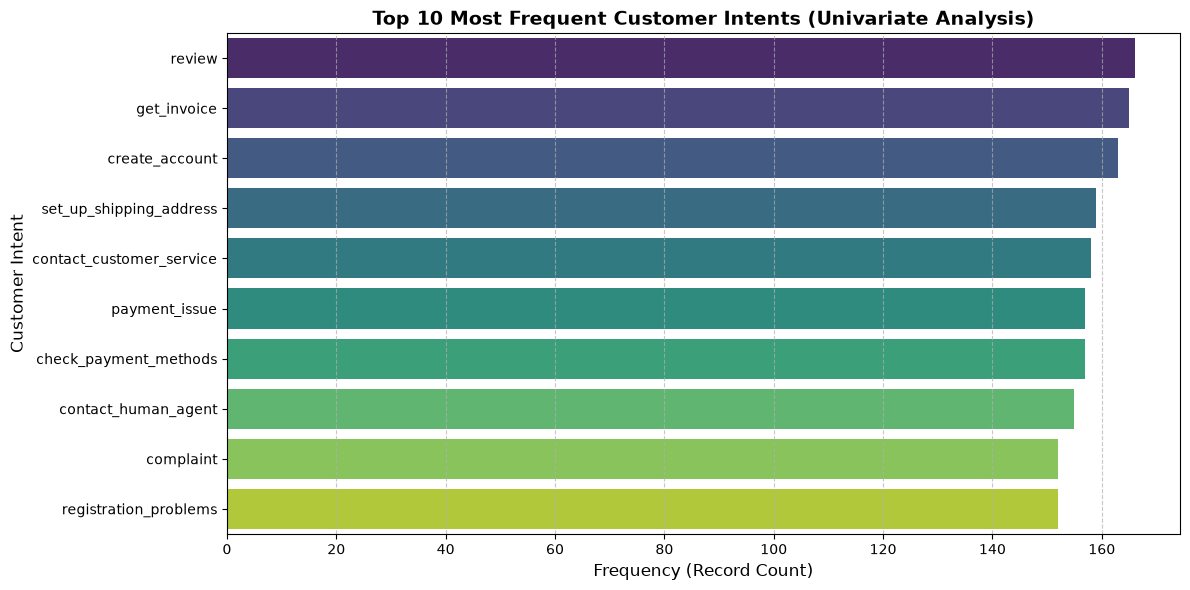

Most frequent intent 'review' comprises 4.25% of total data (<80% threshold, balanced distribution).


In [4]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
top_10_intents = df_cleaned['intent'].value_counts().head(10)
sns.barplot(x=top_10_intents.values, y=top_10_intents.index, palette="viridis")
plt.title("Top 10 Most Frequent Customer Intents (Univariate Analysis)", fontsize=14, fontweight='bold')
plt.xlabel("Frequency (Record Count)", fontsize=12)
plt.ylabel("Customer Intent", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("top10_intents.png", dpi=300)
plt.show()

max_intent_pct = (top_10_intents.iloc[0] / len(df_cleaned)) * 100
print(f"Most frequent intent '{top_10_intents.index[0]}' comprises {max_intent_pct:.2f}% of total data (<80% threshold, balanced distribution).")

#### **1.3.2 Perform Bivariate Analysis [2 marks]**
**The Task:** Read the text from the uploaded Markdown SOP files and fit a `TfidfVectorizer` (with `stop_words='english'`) to transform them into vectors.

**Hints & Tips:**
* Read files into a list of strings first using `open(f, 'r').read()`.
* `TfidfVectorizer(stop_words="english")` removes common words, keeping meaningful terms.
* The resulting matrix shape should be `(num_docs, num_unique_terms)`.

**Learner Inference:** This transforms raw text into math, letting you prove whether your policies are distinct enough for an AI to tell apart.

In [5]:
# YOUR CODE HERE
from sklearn.feature_extraction.text import TfidfVectorizer

sop_files = sorted(glob.glob("corporate_policies/*.md") or glob.glob("Dataset/Dataset/sop_documents/*.md"))
sop_texts = []
sop_doc_names = []

for fpath in sop_files:
    with open(fpath, 'r', encoding='utf-8') as f:
        sop_texts.append(f.read())
        sop_doc_names.append(os.path.basename(fpath).replace('.md', ''))

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(sop_texts)

print(f"TF-IDF Vectorization complete.")
print(f"Matrix shape: {tfidf_matrix.shape} (Documents: {tfidf_matrix.shape[0]}, Vocabulary Terms: {tfidf_matrix.shape[1]})")

TF-IDF Vectorization complete.
Matrix shape: (13, 797) (Documents: 13, Vocabulary Terms: 797)


#### **1.3.3 Generate Visualisations [2 marks]**
**The Task:** Calculate cosine similarity between the TF-IDF vectors of the SOP documents and plot an annotated heatmap.

**Hints & Tips:**
* Use `cosine_similarity` from sklearn and `sns.heatmap` with `annot=True`.
* Diagonal should always be 1.0 (document vs itself).
* Off-diagonal >0.5 = high overlap (RAG may struggle); <0.3 = low overlap (good retrieval).

**Learner Inference:** High overlap (dark off-diagonal squares) means the RAG system struggles to fetch the right doc. Low overlap proves retrieval will be accurate.

In [ ]:
# YOUR CODE HERE
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Compute pairwise cosine similarity matrix
sop_similarity = cosine_similarity(tfidf_matrix)

plt.figure(figsize=(12, 10))
sns.heatmap(
    sop_similarity,
    annot=True,
    fmt=".2f",
    xticklabels=sop_doc_names,
    yticklabels=sop_doc_names,
    cmap='Blues',
    cbar_kws={'label': 'Cosine Similarity'}
)
plt.title("SOP Policy Documents TF-IDF Cosine Similarity Matrix", fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.savefig("sop_similarity_heatmap.png", dpi=300)
plt.show()

off_diag_mask = ~np.eye(sop_similarity.shape[0], dtype=bool)
max_off_diag = sop_similarity[off_diag_mask].max()
mean_off_diag = sop_similarity[off_diag_mask].mean()
print(f"Mean off-diagonal similarity: {mean_off_diag:.3f}")
print(f"Maximum off-diagonal similarity: {max_off_diag:.3f} (< 0.5 threshold, confirming SOP policies are semantically distinct).")

---
## Save Artifacts for Notebook 2

**IMPORTANT:** This cell saves the cleaned DataFrame. Notebook 2 depends on this file.

In [ ]:
# YOUR CODE HERE
df_cleaned.to_csv("sampled_data.csv", index=False)
print(f"Successfully saved sampled_data.csv ({len(df_cleaned)} rows) for Notebook 2.")

---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 2.**

- [ ] Bitext dataset loaded and `.info()` printed
- [ ] Dataset sampled to 4000 rows (or chosen size 1000–5000)
- [ ] Nulls inspected, near-duplicates removed via normalised dedup
- [ ] Top 10 intent bar chart rendered
- [ ] TF-IDF vectorisation completed on SOP documents
- [ ] Cosine similarity heatmap rendered
- [ ] **`sampled_data.csv` saved to disk** ← _CRITICAL for Notebook 2_
- [ ] `corporate_policies/` folder still accessible ← _Needed in Notebooks 2 and 4_

**If any item is unchecked, fix it before moving on.**